In [1]:
import matplotlib.pyplot as plt
from kids.ml.classifiers import XGBClf
from kids.catalog.training_catalog import load_and_prepare_training_catalog, merge_training_catalogs
from kids.training_data import TrainingData
from kids.features import clf_features
from sklearn.metrics import classification_report, ConfusionMatrixDisplay

#### Load data

In [6]:
kids_x_desi = load_and_prepare_training_catalog('../data/KiDS_DR5_WCScut_x_DESI_DR1_columns.csv')
kidx_x_sdss = load_and_prepare_training_catalog('../data/KiDS_DR5_WCScut_x_SDSS_DR17_columns.csv')

merged_catalogs = merge_training_catalogs(kids_x_desi, kidx_x_sdss)

training_data = TrainingData(merged_catalogs, clf_features, train_size=0.6)

In [7]:
X_test, y_test = training_data.get_test_clf()

#### Load Model

In [8]:
model = XGBClf()
model.load('../saved_models/classification/xgb_clf_2026-10-30T11-32-05Z.json')

#### Evaluate

              precision    recall  f1-score   support

           0       0.98      0.99      0.99     62719
           1       0.99      0.99      0.99    309701
           2       0.90      0.83      0.87     25058

    accuracy                           0.98    397478
   macro avg       0.96      0.94      0.95    397478
weighted avg       0.98      0.98      0.98    397478



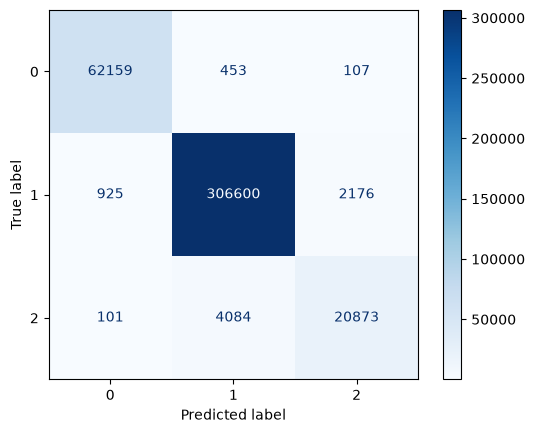

In [9]:
test_preds = model.predict(X_test)
print(classification_report(y_test, test_preds))

ConfusionMatrixDisplay.from_predictions(y_test, test_preds, cmap='Blues')
plt.show()